## Simulation of radioactive decay

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

In [2]:
def radioactive_decay(N0 = 10000, decay_const=0.5):
    
    t = 0
    N_left = [N0]
    
    while N0 != 0:
        for i in range(N0):
            r = np.random.rand(1)
            if r< decay_const:
                N0 -= 1
        N_left.append(N0)
        t += 1

    N_left = np.array(N_left)

    return N_left, t
    

In [3]:
decay_const = np.random.rand(1)
N = 10000

N_left, t = radioactive_decay(N, decay_const)

print(f'costante di decadimento:{decay_const}, tempo:{t}')

costante di decadimento:[0.52168518], tempo:22


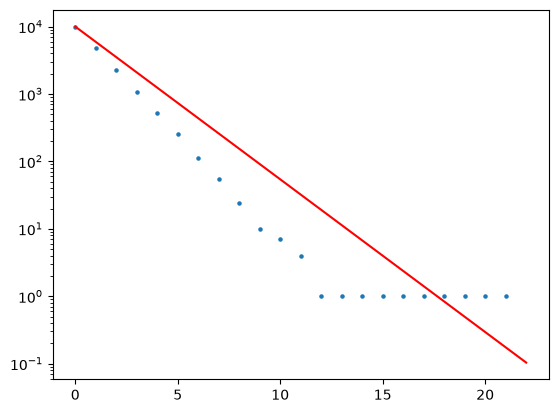

In [4]:
x = np.linspace(0, t, num=t+1)
y = -1*decay_const*x + np.log(10000)

plt.scatter(x, N_left, s=5)
plt.plot(x,np.exp(y), c='red')
plt.yscale('log')
plt.show()

In [5]:
N = np.linspace(100, 1000000, num = 10, dtype='int64')
decay_const = np.random.rand(1)
Ni_left = []
ti = []

for i in N:

    N_left, t = radioactive_decay(i, decay_const)
    Ni_left.append(N_left)
    ti.append(t)    

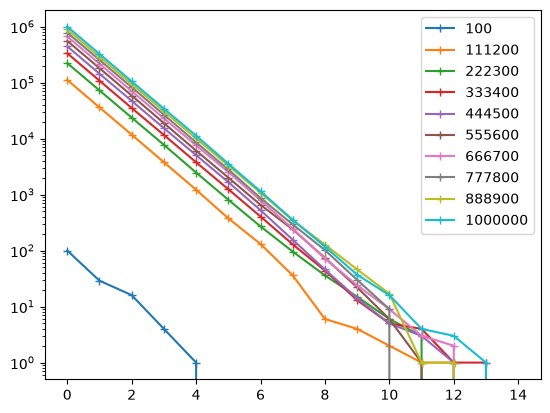

In [6]:
for i in range(len(N)):

    x = np.linspace(0, ti[i], num=ti[i]+1)
    plt.plot(x,Ni_left[i], label=N[i], marker='+')

plt.yscale('log')
plt.legend()
plt.show()

In [7]:
decay_const_i = np.linspace(0.01, 0.9, num = 20)
N = 10000
Ni_left = []
ti = []

for i in decay_const_i:

    N_left, t = radioactive_decay(N, i)
    Ni_left.append(N_left)
    ti.append(t)   

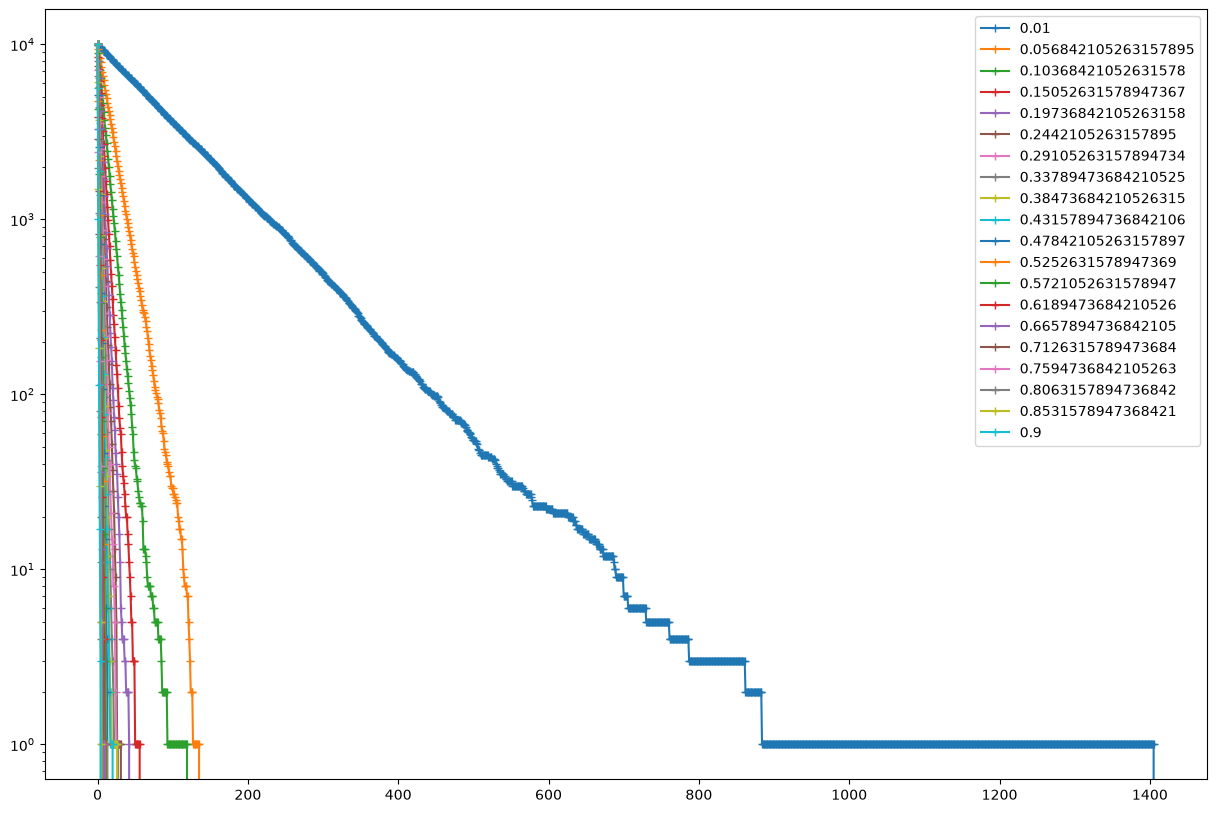

In [8]:
plt.figure(figsize=[15,10])
for i in range(len(decay_const_i)):

    x = np.linspace(0, ti[i], num=ti[i]+1)
    plt.plot(x,Ni_left[i], label=decay_const_i[i], marker='+')

plt.yscale('log')
plt.legend()
plt.show()

## 1D Random walks: properties; comparison numerical/analytical results; convergence

In [9]:
p_right  = 0.5
p_left   = 1 - p_right
N        = 100
li       = []
sposta   = {}
n_player = 1000

for j in range(n_player):
    
    l=0
    sposta[j] = [0]
    
    for i in range(N):

        temp = np.random.rand(1)
        
        if temp < p_right:
            l += 1
        else:
            l -= 1
        sposta[j].append(l)

    li.append(l)        

In [10]:
np.mean(li)

np.float64(-0.436)

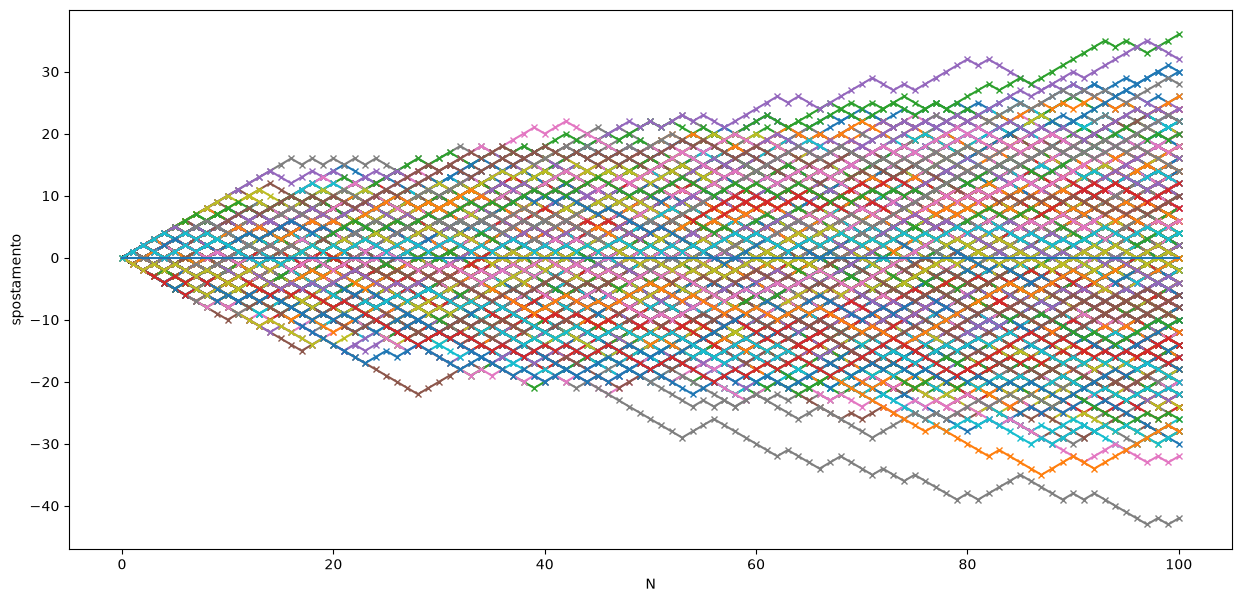

In [11]:
x = np.linspace(0,N,num=N+1)
plt.figure(figsize=[15,7])
for i in sposta:
    plt.plot(x,sposta[i],marker='x', ms=5)

plt.plot(x, x*0)
plt.ylabel('spostamento')
plt.xlabel('N')
plt.show()

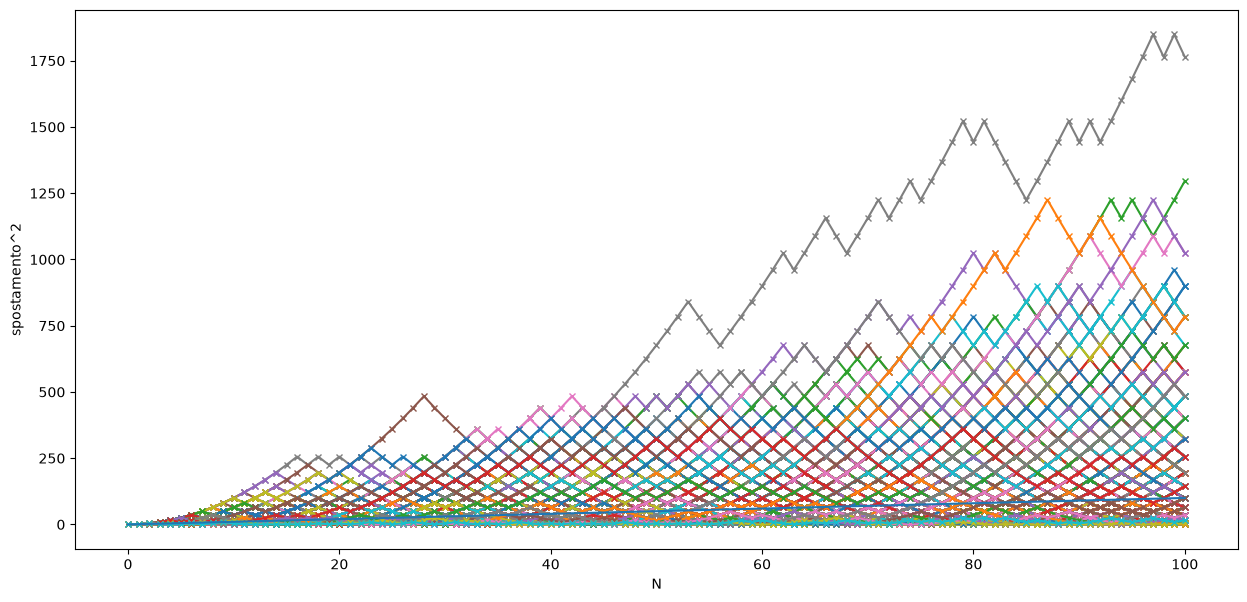

In [12]:
x = np.linspace(0,N,num=N+1)
plt.figure(figsize=[15,7])
for i in sposta:
    plt.plot(x,np.array(sposta[i])**2,marker='x', ms=5)

plt.plot(x, x)
plt.ylabel('spostamento^2')
plt.xlabel('N')
plt.show()

In [13]:
sposta_finale = []

for i in range(len(sposta)):
    sposta_finale.append(sposta[i][-1])

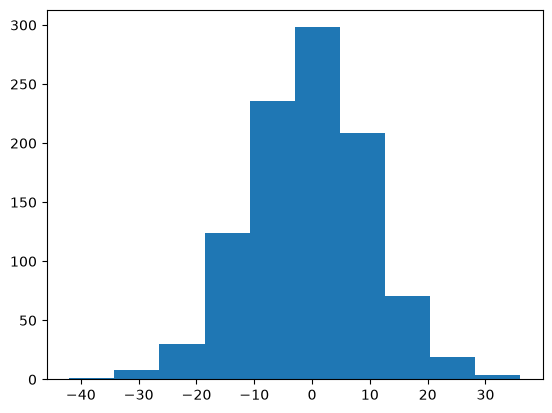

In [14]:
plt.hist(sposta_finale, bins=10)
plt.show()

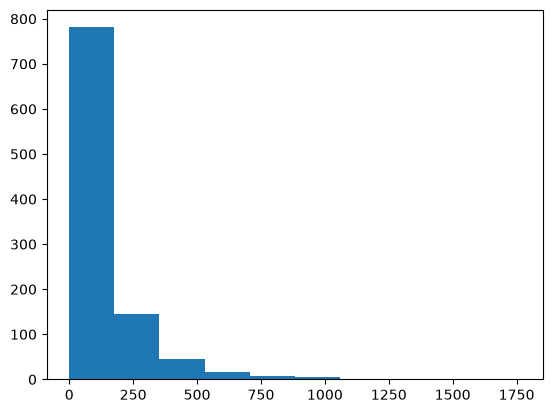

In [15]:
plt.hist(np.array(sposta_finale)**2, bins=10)
plt.show()

In [16]:
df_sposta = pd.DataFrame.from_dict(sposta, orient='index') 
media_sposta = np.mean(df_sposta, axis=0)
media_quadrata_sposta = np.mean(df_sposta**2, axis=0)
media_sposta_fin = np.mean(df_sposta[N-1])
media_quadrata_sposta_fin = np.mean(df_sposta[N-1]**2)

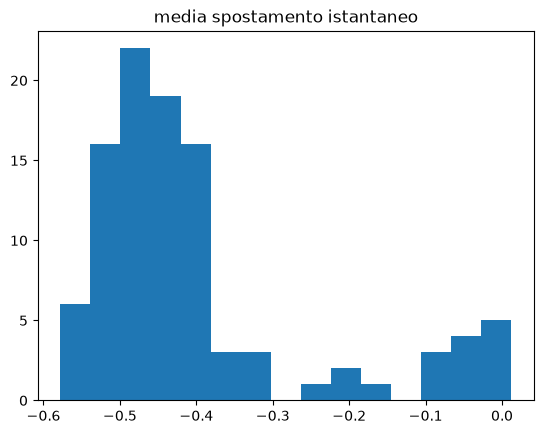

In [17]:
plt.hist(media_sposta, bins=15)
plt.title('media spostamento istantaneo')
plt.show()

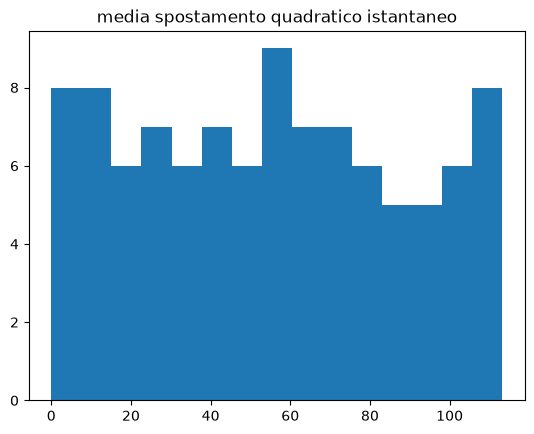

In [18]:
plt.hist(media_quadrata_sposta, bins=15)
plt.title('media spostamento quadratico istantaneo')
plt.show()

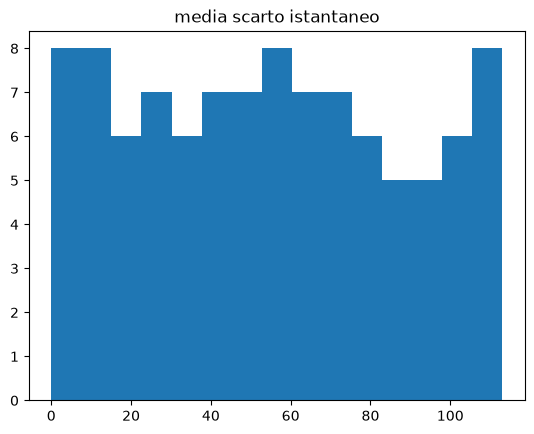

In [19]:
plt.hist(media_quadrata_sposta - media_sposta**2, bins=15)
plt.title('media scarto istantaneo')
plt.show()

In [20]:
accuracy = abs((media_quadrata_sposta_fin - media_sposta_fin**2)/100 -1)
print(accuracy)

0.12114943999999994


In [21]:
p_right = 0.5
p_left = 1 - p_right
n_player = 1000

Ni = np.linspace(100, 1000, num=100, dtype=int)

std_results = []
mean_results = []

for N in Ni:
    li = []
    
    for j in range(n_player):
        l = 0

        for i in range(N):
            temp = np.random.rand()
            if temp < p_right:
                l += 1
            else:
                l -= 1
        li.append(l)
    
    mean_results.append(np.mean(li))
    std_results.append(np.std(li))

<>:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_6987/1396140597.py:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.plot(Ni, np.sqrt(Ni), label="Teorica ($\sqrt{N}$)", linestyle="--")


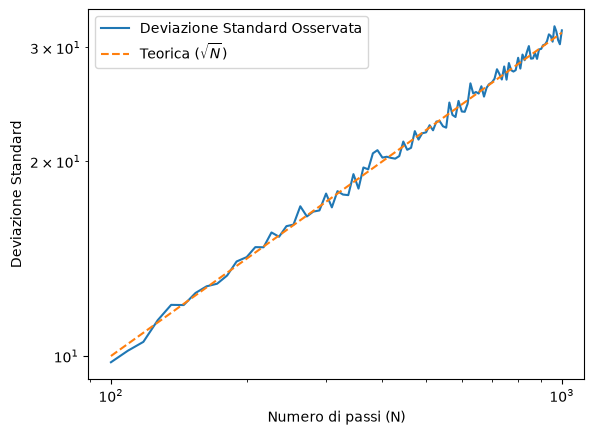

In [22]:
plt.plot(Ni, std_results, label="Deviazione Standard Osservata")
plt.plot(Ni, np.sqrt(Ni), label="Teorica ($\sqrt{N}$)", linestyle="--")
plt.xlabel("Numero di passi (N)")
plt.ylabel("Deviazione Standard")
plt.yscale('log')
plt.xscale('log')
plt.legend()
plt.show()

In [23]:
N = 8
p_right = 0.5
p_left = 1 - p_right
num_simulations = 100000

steps = np.random.choice([1, -1], size=(num_simulations, N), p=[p_right, p_left])
final_positions = np.sum(steps, axis=1)

x_values = np.arange(-N, N + 1, 2)

counts, _ = np.histogram(final_positions, bins=np.append(x_values - 1, x_values[-1] + 1))
p_simulated = counts / num_simulations

p_theoretical = []
for x in x_values:
    n_plus = (N + x) // 2   
    n_minus = (N - x) // 2  
    
    if 0 <= n_plus <= N:
    
        comb = math.comb(N, n_plus)
        prob = comb * (p_right ** n_plus) * (p_left ** n_minus)
        p_theoretical.append(prob)
    else:
        p_theoretical.append(0)

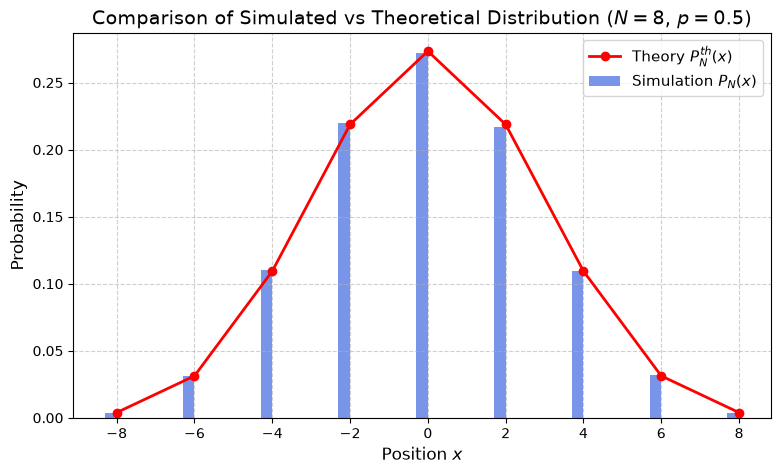

In [24]:
plt.figure(figsize=(9, 5))
plt.bar(x_values - 0.15, p_simulated, width=0.3, label='Simulation $P_N(x)$', alpha=0.7, color='royalblue')
plt.plot(x_values, p_theoretical, 'ro-', label='Theory $P_N^{th}(x)$', linewidth=2, markersize=6)

plt.xlabel('Position $x$', fontsize=12)
plt.ylabel('Probability', fontsize=12)
plt.title(f'Comparison of Simulated vs Theoretical Distribution ($N = {N}$, $p = 0.5$)', fontsize=14)
plt.xticks(x_values)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

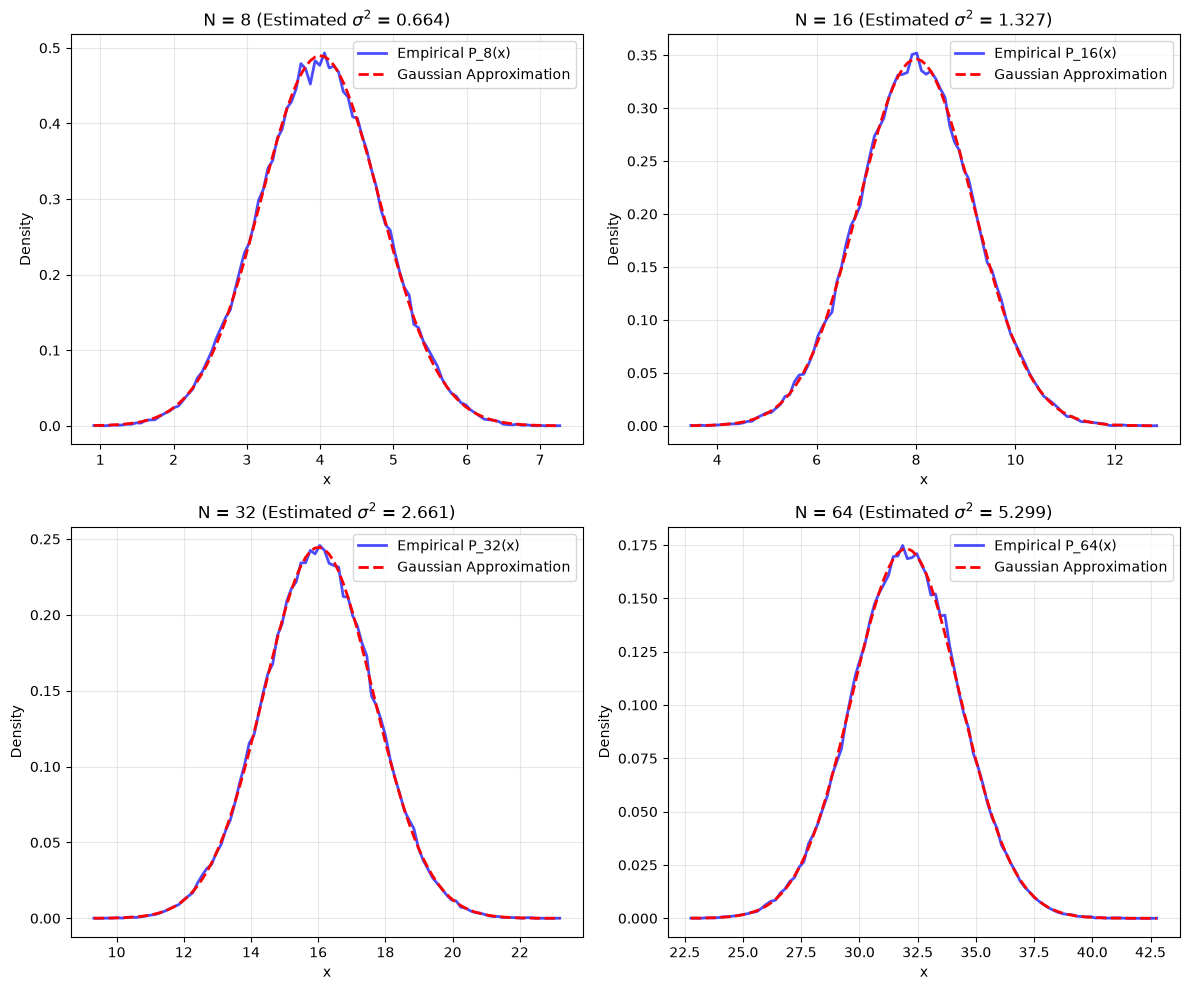

In [25]:
N_values = [8, 16, 32, 64]
num_samples = 100000  
plt.figure(figsize=(12, 10))

for idx, N in enumerate(N_values, 1):

    uniform_vars = np.random.uniform(0, 1, size=(num_samples, N))
    X = np.sum(uniform_vars, axis=1)
    
    mean_x = np.mean(X)
    var_x = np.var(X, ddof=1)
    std_x = np.sqrt(var_x)
    
    count, bins = np.histogram(X, bins=100, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    
    gaussian_approx = (1 / (np.sqrt(2 * np.pi * var_x))) * np.exp(-((bin_centers - mean_x) ** 2) / (2 * var_x))
    
    plt.subplot(2, 2, idx)
    plt.plot(bin_centers, count, label=f'Empirical P_{N}(x)', color='blue', alpha=0.7, lw=2)
    plt.plot(bin_centers, gaussian_approx, label='Gaussian Approximation', color='red', linestyle='--', lw=2)
    plt.title(f'N = {N} (Estimated $\\sigma^2$ = {var_x:.3f})')
    plt.xlabel('x')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2D Random walks

In [42]:
N = 100
n_walkers = 1000
spostamenti = {}

for i in range(n_walkers):
    l = (0, 0)
    spostamenti[f'walker_{i}'] = [l]

    for j in range(N):
        theta = np.random.rand(1) * 2 * np.pi

        x = np.cos(theta)[0] + l[0]
        y = np.sin(theta)[0] + l[1]

        l = (x, y)
        spostamenti[f'walker_{i}'].append((x, y))

df_sposta_2d = pd.DataFrame.from_dict(spostamenti, orient='index')

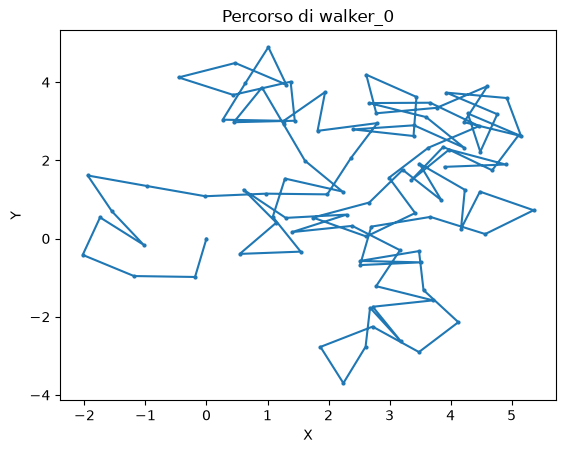

In [43]:
x = [pos[0] for pos in df_sposta_2d.loc['walker_0']]
y = [pos[1] for pos in df_sposta_2d.loc['walker_0']]

plt.plot(x, y, marker='o', markersize=2)
plt.title("Percorso di walker_0")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

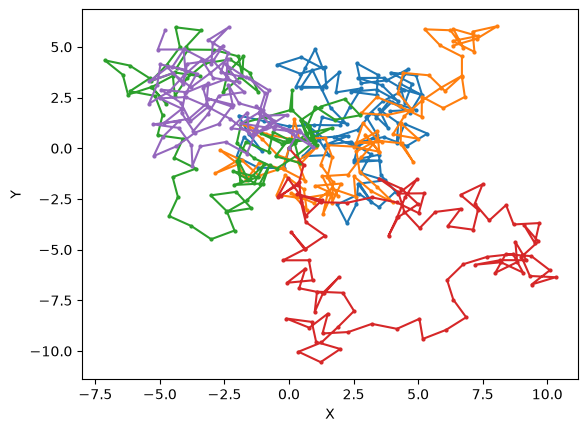

In [48]:
for i in range(5):
    x = [pos[0] for pos in df_sposta_2d.loc[f'walker_{i}']]
    y = [pos[1] for pos in df_sposta_2d.loc[f'walker_{i}']]

    plt.plot(x, y, marker='o', markersize=2)
plt.xlabel("X")
plt.ylabel("Y")
plt.show()    

In [45]:
Ni = [8,16,32,64]
spostamenti_N = {}


for n in Ni:

    l = (0, 0)
    spostamenti_N[f'walker_{n}'] = [l]

    for j in range(N):
        theta = np.random.rand(1) * 2 * np.pi

        x = np.cos(theta)[0] + l[0]
        y = np.sin(theta)[0] + l[1]

        l = (x, y)
        spostamenti_N[f'walker_{n}'].append((x, y))

df_sposta_2d_N = pd.DataFrame.from_dict(spostamenti_N, orient='index')           

In [46]:
df_sposta_2d_N.head()

,0,1,2,3,4,5,6,7,8,9,...,91,92,93,94,95,96,97,98,99,100
walker_8,"(0, 0)","(-0.8295773787750728, -0.5583917734213851)","(-1.1640686179517674, 0.38400708635829395)","(-2.147716064905345, 0.5641117784174094)","(-1.1697082907392256, 0.35554333960023754)","(-1.7132364956928692, 1.194934244018358)","(-1.303370374212408, 2.1070799354857703)","(-2.0505869851075675, 2.7716605072769953)","(-1.8366753886099023, 1.7948074841031811)","(-1.1439646420923433, 2.5160230008934716)",...,"(-3.072878395839416, 7.591235777376047)","(-2.20287941165466, 7.09818226352842)","(-2.997869123690445, 7.704805175853086)","(-2.698052371462472, 6.750808365018024)","(-3.4304570569074597, 6.069938791062609)","(-2.8516753377928317, 6.8854212995315)","(-2.5447941122426627, 7.837169119809974)","(-1.559446318556853, 8.007726223087753)","(-1.4726717671729028, 7.011498248559777)","(-2.0251875123484515, 7.8450007088639495)"
walker_16,"(0, 0)","(-0.2945759578861617, -0.955628068358946)","(0.6947960936152875, -0.8102219346925369)","(1.3545427823386156, -0.05873387309833955)","(0.9151607790638288, 0.8395664414948566)","(-0.04741987685894855, 1.1105617935643632)","(-1.047090471890238, 1.1362269728894259)","(-1.2718024939738304, 2.110652191739545)","(-1.6539612890749043, 3.03474886164313)","(-2.2948386990266165, 3.802392102617468)",...,"(-5.838684652185968, 9.942336115950972)","(-6.836784511361319, 9.880718982666925)","(-6.405816217984237, 10.783086053267159)","(-5.466473490300409, 10.440106112239251)","(-4.494224242049774, 10.674053540684353)","(-3.5768954928362433, 11.072184129645237)","(-4.575583433482582, 11.020974782768175)","(-4.12742324008187, 10.127021517182643)","(-3.5004011631587835, 10.90602300309333)","(-2.5253065133655386, 10.684233860111556)"
walker_32,"(0, 0)","(-0.9170145959932382, -0.39885364575914073)","(0.00320928749700633, -0.007461254093011405)","(1.003199091339066, -0.011977027771908885)","(0.46874777910705834, 0.8332222356290272)","(1.193999370354663, 0.14473830016443168)","(2.1639311368096683, -0.09863870865413574)","(1.3916092831183442, -0.7338701265726744)","(0.39538301524793884, -0.6470759838843377)","(-0.6032514091135248, -0.5948334104384592)",...,"(-9.217638314190287, -0.3905667598406256)","(-8.499347791017431, -1.0863100489351494)","(-9.454841288856505, -1.3813222106967469)","(-8.929277864837742, -2.2320766331558213)","(-8.73406184030223, -3.2128369013990605)","(-9.161771229450121, -4.116753201968278)","(-8.351533133637886, -4.7028540705007895)","(-9.264030900336264, -5.11193575643952)","(-8.478902760642987, -4.492602401725136)","(-8.37481083775315, -5.487170082473458)"
walker_64,"(0, 0)","(-0.32258432321531694, -0.9465407304578688)","(-0.26040939530244656, 0.05152453711686722)","(-0.011717650282563025, -0.9170581469937694)","(0.9783598472127607, -0.7765357325774304)","(0.31875153425940184, -0.02492621062948175)","(-0.4261432602404318, 0.6422557324168289)","(0.44219391112926154, 0.1462813814492815)","(-0.5166843805205937, 0.4300989668851652)","(-1.5025908432960344, 0.262801487353587)",...,"(1.4943949378612202, -14.307577394800948)","(1.8542783673743288, -15.240574670875151)","(0.8695912035111426, -15.414905360436899)","(1.8687129811413112, -15.456806117770533)","(2.1249750118896373, -14.490198766465596)","(1.3660195947575537, -13.83905617470411)","(2.350390834398144, -14.015162002456766)","(3.350160627417047, -14.036618026481248)","(3.7596995680497134, -13.124325389162786)","(3.1619445942280926, -12.322646531220585)"


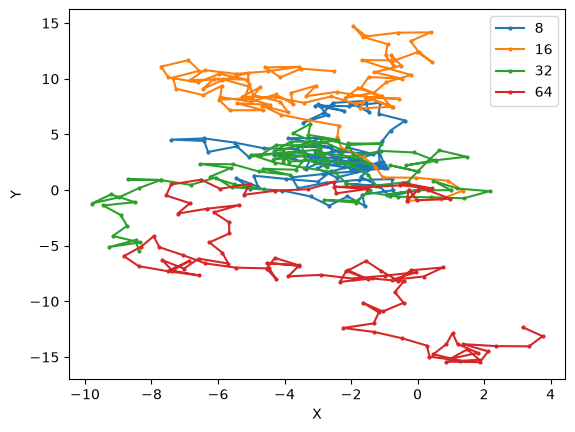

In [51]:
for i in Ni:
    x = [pos[0] for pos in df_sposta_2d_N.loc[f'walker_{i}']]
    y = [pos[1] for pos in df_sposta_2d_N.loc[f'walker_{i}']]

    plt.plot(x, y, marker='o', markersize=2, label=f'{i}')

plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.show()  

In [54]:
delta_R = []

for i in Ni:
    x = np.array([pos[0] for pos in df_sposta_2d_N.loc[f'walker_{i}']])
    y = np.array([pos[1] for pos in df_sposta_2d_N.loc[f'walker_{i}']])

    x_quadro_mean = np.mean(x**2)
    y_quadro_mean = np.mean(y**2)
    x_mean        = np.mean(x)
    y_mean        = np.mean(y)

    R = x_quadro_mean + y_quadro_mean - x_mean**2 - y_mean**2

    delta_R.append(R)
    

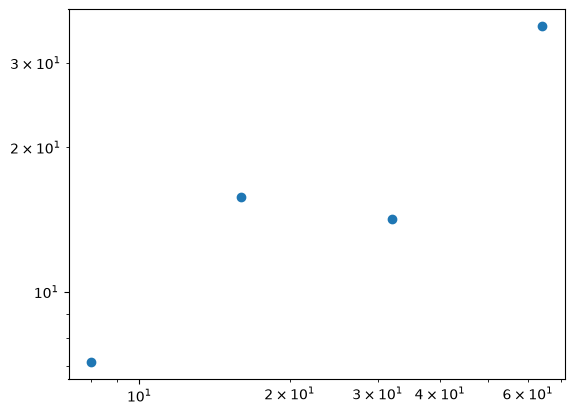

In [57]:
plt.scatter(Ni, delta_R)
plt.xscale('log')
plt.yscale('log')
plt.show()

In [64]:
N = 100
n_walkers = 1000
spostamenti = {}

for i in range(n_walkers):
    l = (0, 0)
    spostamenti[f'walker_{i}'] = [l]

    for j in range(N):

        x = np.random.rand(1)[0]*2 - 1 
        y = np.random.rand(1)[0]*2 - 1 
        norm = np.sqrt(x**2 + y**2)
        x = x/norm + l[0]
        y = y/norm + l[1]


        l = (x, y)
        spostamenti[f'walker_{i}'].append((x, y))

df_sposta_2d = pd.DataFrame.from_dict(spostamenti, orient='index')

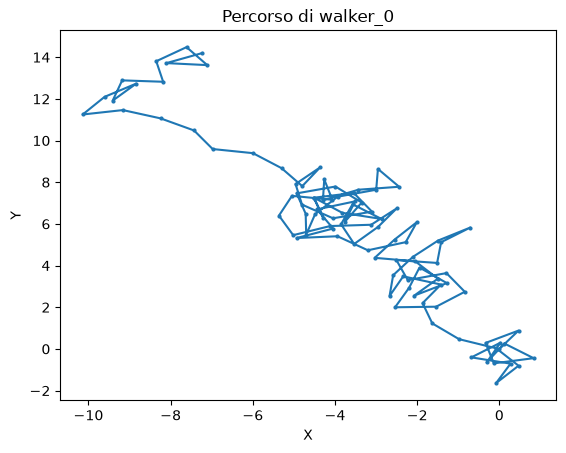

In [65]:
x = [pos[0] for pos in df_sposta_2d.loc['walker_0']]
y = [pos[1] for pos in df_sposta_2d.loc['walker_0']]

plt.plot(x, y, marker='o', markersize=2)
plt.title("Percorso di walker_0")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [71]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

x = [float(pos[0]) for pos in df_sposta_2d.loc['walker_0']]
y = [float(pos[1]) for pos in df_sposta_2d.loc['walker_0']]

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(min(x) - 1, max(x) + 1)
ax.set_ylim(min(y) - 1, max(y) + 1)

line, = ax.plot([], [], 'b-', lw=1.5)
point, = ax.plot([], [], 'ro', markersize=6)

def init():
    line.set_data([], [])
    point.set_data([], [])
    return line, point

def update(frame):
    line.set_data(x[:frame+1], y[:frame+1])
    point.set_data([x[frame]], [y[frame]])
    return line, point

anim = FuncAnimation(fig, update, init_func=init, frames=len(x), interval=50, blit=True)

# Genera l'HTML senza chiudere prima la figura
display(HTML(anim.to_jshtml()))

<IPython.core.display.Javascript object>